# Stage-dependent capacity prediction in doped LNCM cathodes

Run all cells to verify the fitted models against the archived holdout predictions,
compare cross-validation and test metrics, and view the manuscript figures.
The notebook uses the deposited split, predictions and figure previews.

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("ncm_dataset.csv", index_col="sample_index", float_precision="round_trip")
bundle = joblib.load("ncm_models.joblib")

# Translate manuscript headers to the names stored in the fitted estimators.
aliases = {"x_dopant": "dopant_M", "A_r,dopant": "Mr_dopant", "ΔIR": "△IR", "ΔEN": "△EN"}
X = data.rename(columns=aliases)[list(bundle["features"])]
assert len(data) == 213 and data.index.is_unique

## Model performance

Mean CV R² gives each of the five validation folds equal weight.
Pooled OOF R² uses all 170 validation predictions together.
Test RMSE is in mAh g⁻¹.

In [2]:
rows = []
for (model, stage), fitted in bundle["models"].items():
    saved = bundle["predictions"][model, stage].set_index("sample_index")
    held_out = saved.query("dataset == 'Independent_test'")
    assert len(held_out) == 43
    np.testing.assert_allclose(held_out.actual, data.loc[held_out.index, stage], rtol=0, atol=1e-10)
    predicted = fitted.predict(X.loc[held_out.index])
    np.testing.assert_allclose(predicted, held_out.predicted, rtol=0, atol=1e-7)

    oof = saved.query("dataset == 'CV_validation'")
    fold_r2 = [r2_score(fold.actual, fold.predicted) for _, fold in oof.groupby("fold")]
    rows.append((model, stage, np.mean(fold_r2), r2_score(oof.actual, oof.predicted),
                 r2_score(held_out.actual, predicted),
                 mean_squared_error(held_out.actual, predicted) ** 0.5))

metrics = pd.DataFrame(rows, columns=["Model", "Stage", "Mean CV R²", "Pooled OOF R²",
                                     "Test R²", "Test RMSE"])
display(metrics.round(4))

Model,Stage,Mean CV R²,Pooled OOF R²,Test R²,Test RMSE
GBR,IC,0.7410,0.7350,0.7596,17.7992
GBR,EC50,0.6974,0.6935,0.7816,15.6035
GBR,EC100,0.6200,0.6237,0.6968,18.9668
RF,IC,0.6991,0.6939,0.7539,18.0076
RF,EC50,0.6329,0.6321,0.7408,16.9983
RF,EC100,0.5828,0.5857,0.6493,20.4004
SVR,IC,0.6545,0.6610,0.6344,21.9490
SVR,EC50,0.5755,0.5829,0.7142,17.8481
SVR,EC100,0.5344,0.5465,0.6452,20.5183
GPR,IC,0.6795,0.6904,0.6891,20.2395


## Figures

The previews below are rendered from the archived manuscript figures.
The full reproduction code is maintained in the [original research repository](https://github.com/xyongkang215-ops/ncm-stage-capacity-ml).

### Figure 2

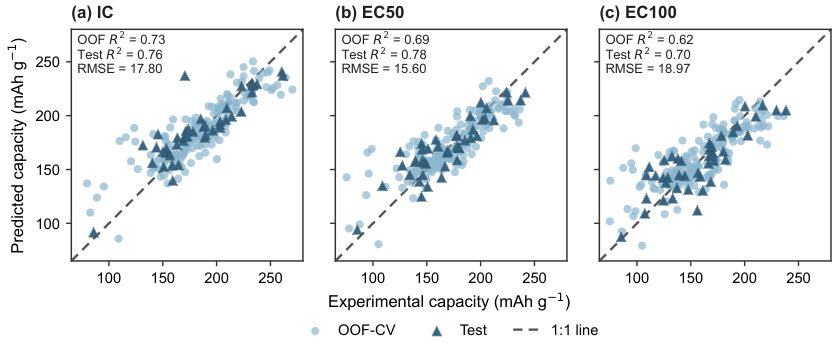

### Figure 3

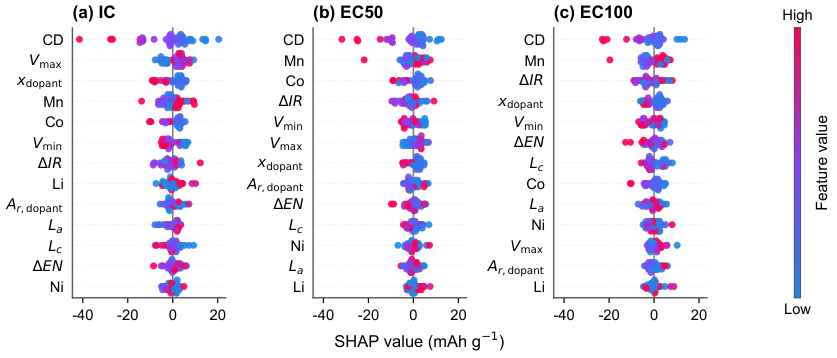

### Figure 4

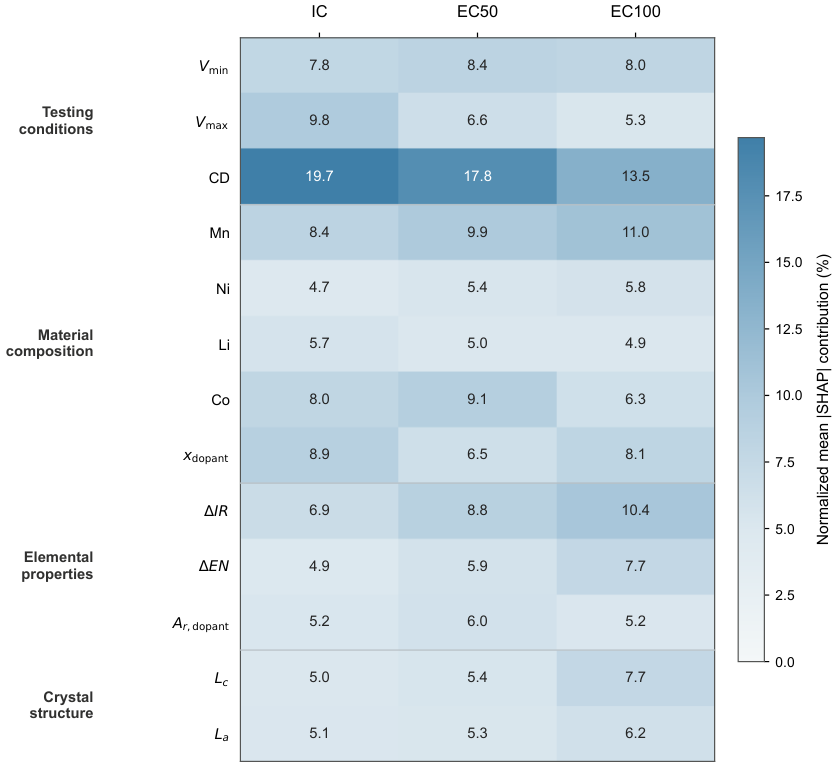

### Figure 5

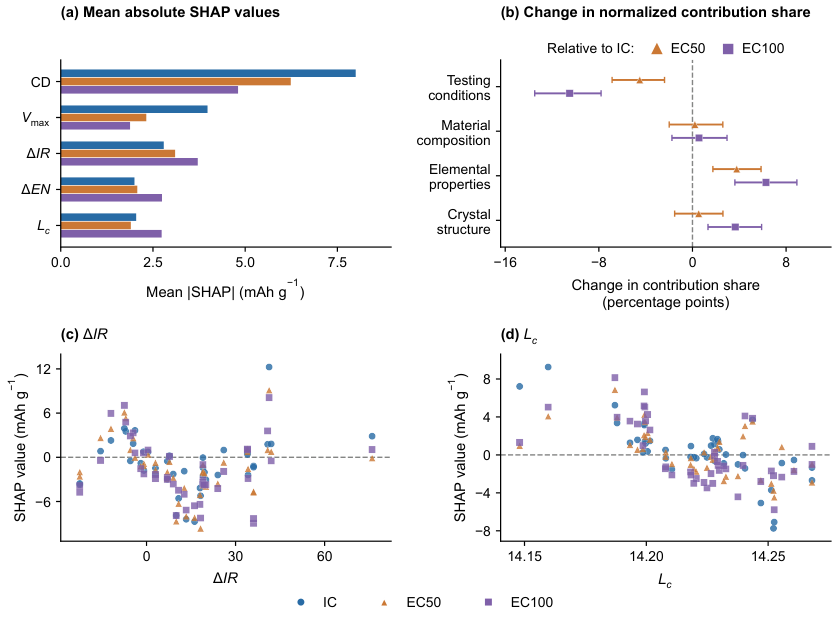

### Figure S1a

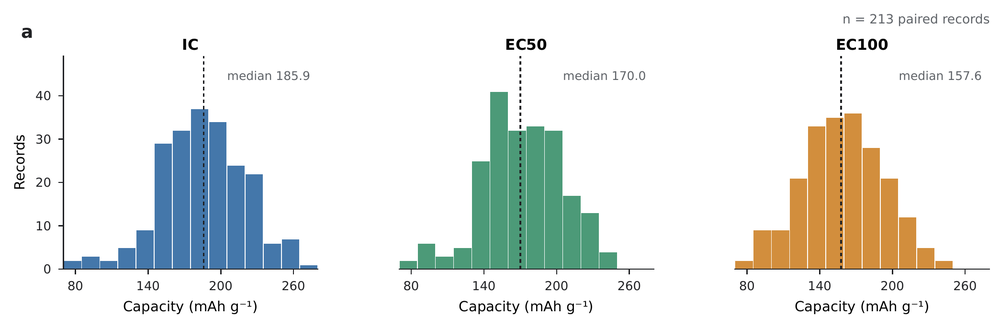

### Figure S1b

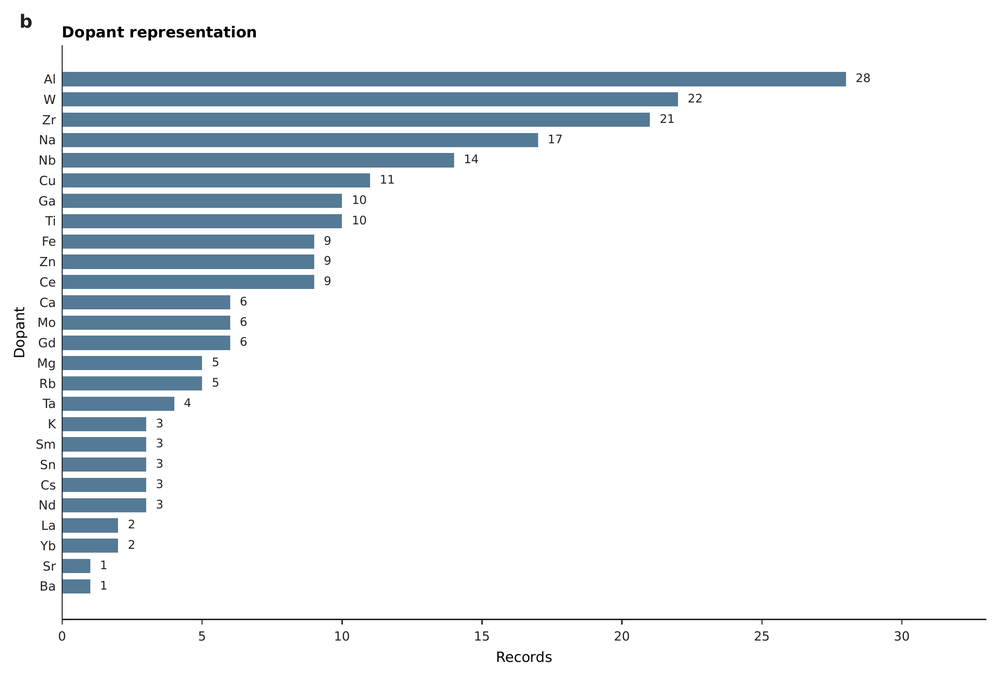

### Figure S2

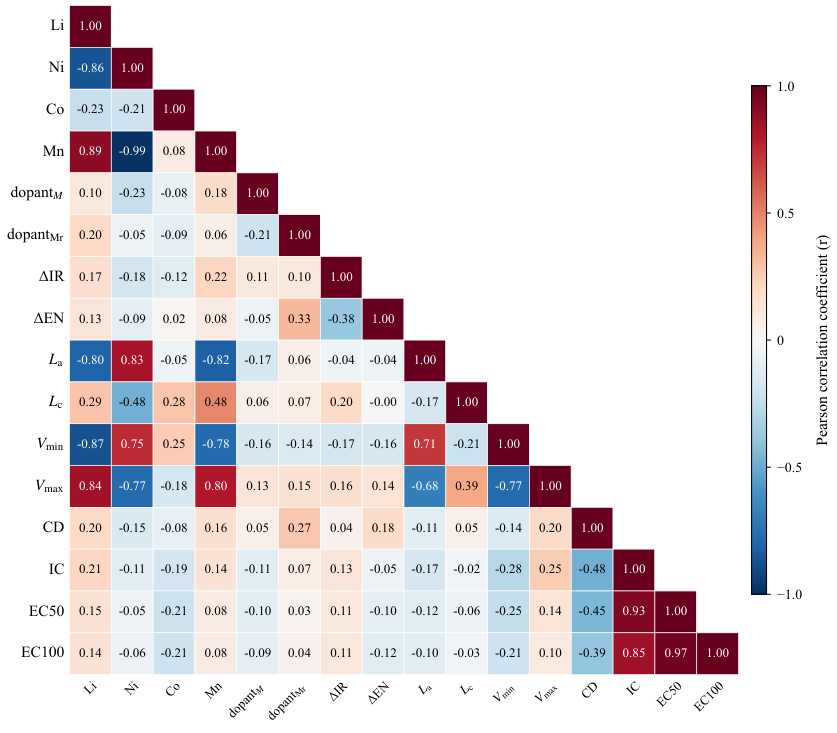

In [3]:
for number in ("2", "3", "4", "5", "S1a", "S1b", "S2"):
    display(Markdown(f"### Figure {number}"))
    display(Image(data=bundle["figures"][number], width=850))